# Epistemic uncertainty & the blind-spot quadrant (K+1 outlier exposure)

OSSIM split on cached CLIP features -> a K+1 head (kkc classes -> outputs 0..K-1, kuc classes -> a learned **unknown** output) -> MC-dropout decomposition of predictive uncertainty:

- **TU** total = entropy of the mean prediction
- **AU** aleatoric = mean member entropy (here: mean MC-pass entropy)
- **EU** epistemic = TU - AU (BALD) -- high where the head has no training support

**Blind spot** = a row that looks *confident* (TU below the known-rows' 90th percentile) while its EU is *above* the known-rows' 90th percentile -- the head is sure of something its training cannot support. Thresholds are set on known rows only, so the known group sits at ~10% by construction; the uuc (never-seen) fraction is the real read.

Runs on Colab (Drive path) and locally (falls back to `cache/features/features.pt`).

In [1]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    %pip install -q pytorch-ood
    FEATURE_PATH = '/content/drive/MyDrive/checkpoints/checkpoints/REACH/features.pt'
except ModuleNotFoundError:
    FEATURE_PATH = 'cache/features/features.pt'      # local fallback
    print('not on Colab ->', FEATURE_PATH)

not on Colab -> cache/features/features.pt


In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from pytorch_ood.dataset.ossim import DynamicOSS
from sklearn.metrics import roc_auc_score, roc_curve

def load_cached(path):
    b = torch.load(path)
    entry = b['cifar10_test']
    X = entry['X'].float().numpy()          # fp16 -> fp32 before any math
    y = entry['y'].numpy().astype(np.int64)
    assert X.ndim == 2 and len(X) == len(y), (X.shape, y.shape)
    print(f'{path}: X {X.shape}, classes {np.unique(y).tolist()}, '
          f'mean norm {np.linalg.norm(X, axis=1).mean():.3f}')
    return X, y

In [3]:
def make_oss(path, kuc=1, uuc_val=2, uuc_test=5,
             train_size=0.7, val_size=0.2, test_size=0.1, seed=0):
    """train sees kkc (+ kuc, outlier exposure); val/test add classes train never saw."""
    X, y = load_cached(path)
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    oss = DynamicOSS(ds, train_size=train_size, val_size=val_size,
                     test_size=test_size, kuc=kuc,
                     uuc_val=uuc_val, uuc_test=uuc_test, seed=seed)
    kkc, kuc_, uuc = set(oss.kkc), set(oss.kuc), set(oss.uuc)
    assert kkc.isdisjoint(uuc) and kkc.isdisjoint(kuc_)
    assert len(kkc) >= 2, (f'only {len(kkc)} known-known classes left; '
                           f'kuc + uuc_val + uuc_test must stay below the class count')
    parts = {'train': oss.train_dataset(in_dist=True, out_dist=True),
             'val':   oss.val_dataset(in_dist=True, out_dist=True),
             'test':  oss.test_dataset(in_dist=True, out_dist=True)}
    idx = {k: np.asarray(v.indices) for k, v in parts.items()}
    for name, ix in idx.items():
        print(f'  {name:5s}: {len(ix):5d} rows, classes {np.unique(y[ix]).tolist()}')
    assert not (set(idx['train']) & set(idx['val']) | set(idx['train']) & set(idx['test'])
                | set(idx['val']) & set(idx['test'])), 'split leak'
    return dict(X=X, y=y, idx=idx, kkc=sorted(kkc), kuc=sorted(kuc_), uuc=sorted(uuc))

world = make_oss(FEATURE_PATH, kuc=1, uuc_val=2, uuc_test=5, seed=0)
X, y = world['X'], world['y']
print('kkc', world['kkc'], '| kuc', world['kuc'], '| uuc', world['uuc'])

cache/features/features.pt: X (10000, 512), classes [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], mean norm 1.000


  train:  2100 rows, classes [1, 4, 8]
  val  :  2600 rows, classes [1, 2, 4, 6, 8]
  test :  5300 rows, classes [0, 1, 3, 4, 5, 7, 8, 9]
kkc [np.int64(1), np.int64(8)] | kuc [np.int64(4)] | uuc [np.int64(0), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(9)]


## K+1 outlier exposure

The head has `len(kkc) + 1` outputs: kkc classes map to `0..K-1`, and **every kuc class maps to output K** -- a learnable 'unknown' logit trained on real outlier data. Dropout inside the head is what makes the MC passes (and therefore EU) possible.

In [4]:
K = len(world['kkc'])
lut = torch.full((1024,), -1, dtype=torch.long)
for k, c in enumerate(world['kkc']):
    lut[c] = k
for c in world['kuc']:
    lut[c] = K                                  # all kuc ids -> the unknown output

train_idx = world['idx']['train']                # kkc + kuc rows, by design
train_ds = TensorDataset(torch.from_numpy(X[train_idx]).float(),
                         lut[torch.from_numpy(y[train_idx]).long()])
train_ld = DataLoader(train_ds, batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(0))
print('train rows:', len(train_ds), '(kkc + kuc, mapped to', K + 1, 'outputs)')

train rows: 2100 (kkc + kuc, mapped to 3 outputs)


In [5]:
class HeadDrop(nn.Module):
    def __init__(self, d_in, hidden=128, k_total=3, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(),
                                 nn.Dropout(p), nn.Linear(hidden, k_total))
    def forward(self, x):
        return self.net(x)

head = HeadDrop(X.shape[1], k_total=K + 1)
opt = torch.optim.Adam(head.parameters(), lr=1e-3)
torch.manual_seed(0)
for epoch in range(1, 301):
    head.train()
    tot, n = 0.0, 0
    for xb, yb in train_ld:
        opt.zero_grad()
        loss = F.cross_entropy(head(xb), yb)
        loss.backward(); opt.step()
        tot += float(loss.detach()) * len(yb); n += len(yb)
    if epoch % 50 == 0 or epoch == 1:
        print(f'epoch {epoch:03d}  loss {tot / n:.4f}')

# sanity: an untrained/wrong head in scope produces uniform predictions (entropy = log K+1)
head.eval()
with torch.no_grad():
    train_acc = float((head(train_ds.tensors[0]).argmax(1) == train_ds.tensors[1]).float().mean())
print(f'train accuracy: {train_acc:.4f}')
assert train_acc > 0.9, 'head looks untrained -- do not trust any uncertainty below'

epoch 001  loss 1.0281


epoch 050  loss 0.0064


epoch 100  loss 0.0018


epoch 150  loss 0.0011


epoch 200  loss 0.0003


epoch 250  loss 0.0002


epoch 300  loss 0.0001
train accuracy: 1.0000


## MC-dropout decomposition and group readout

T stochastic passes with dropout active; the decomposition is computed on the **test** rows, grouped by what each class is to the head: `kkc` (seen), `kuc` (trained as unknown), `uuc` (never seen -- the honest test).

In [6]:
T = 30
head.train()                                   # dropout stochastic during the passes
Xt = torch.from_numpy(X[world['idx']['test']]).float()
yt = y[world['idx']['test']]
with torch.no_grad():
    P = torch.stack([F.softmax(head(Xt), dim=1) for _ in range(T)]).numpy()

mean = P.mean(0)
TU = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1)
AU = -(P * np.log(np.clip(P, 1e-12, None))).sum(-1).mean(0)
EU = TU - AU                                   # epistemic (BALD), nats
p_unknown = mean[:, K]

masks = {'kkc': np.isin(yt, world['kkc']),
         'kuc': np.isin(yt, world['kuc']),
         'uuc': np.isin(yt, world['uuc'])}
print(f"{'group':6s} {'n':>5s} {'TU':>7s} {'AU':>7s} {'EU':>7s} {'P(unk)':>7s}")
for g, m in masks.items():
    print(f'{g:6s} {m.sum():5d} {TU[m].mean():7.4f} {AU[m].mean():7.4f} '
          f'{EU[m].mean():7.4f} {p_unknown[m].mean():7.4f}')

print('\nEU        AUROC kkc vs uuc:', round(roc_auc_score(masks["uuc"].astype(int), EU), 3))
print('P(unknown) AUROC uuc:      ', round(roc_auc_score(masks["uuc"].astype(int), p_unknown), 3))
fpr, tpr, _ = roc_curve(masks['uuc'].astype(int), p_unknown)
print('P(unknown) FPR@95%TPR uuc: ', round(float(fpr[np.searchsorted(tpr, 0.95)]), 3),
      '(kuc AUROC is optimistic: class 4 was trained as unknown)')

group      n      TU      AU      EU  P(unk)
kkc      200  0.0078  0.0064  0.0014  0.0002
kuc      100  0.0230  0.0174  0.0055  0.9891
uuc     5000  0.2251  0.1780  0.0472  0.5478

EU        AUROC kkc vs uuc: 0.944
P(unknown) AUROC uuc:       0.666
P(unknown) FPR@95%TPR uuc:  0.407 (kuc AUROC is optimistic: class 4 was trained as unknown)


## The blind-spot quadrant

Thresholds are the known rows' 90th percentiles. A row is in the blind spot when it *looks* confident (`TU <= q_ent`) while its EU is high (`EU > q_eu`) -- confidently unsupported. kkc sits near 10% by construction; the uuc fraction says how often the head is confidently wrong about what it never saw.

In [7]:
q_ent = np.quantile(TU[masks['kkc']], .90)
q_eu  = np.quantile(EU[masks['kkc']], .90)
blind = (TU <= q_ent) & (EU > q_eu)
print(f'thresholds from known rows: TU <= {q_ent:.3f}, EU > {q_eu:.3f}')
for g, m in masks.items():
    print(f'{g:4s}: n {m.sum():5d}  blind-spot frac {blind[m].mean():.3f}')

thresholds from known rows: TU <= 0.001, EU > 0.000
kkc : n   200  blind-spot frac 0.000
kuc : n   100  blind-spot frac 0.010
uuc : n  5000  blind-spot frac 0.003


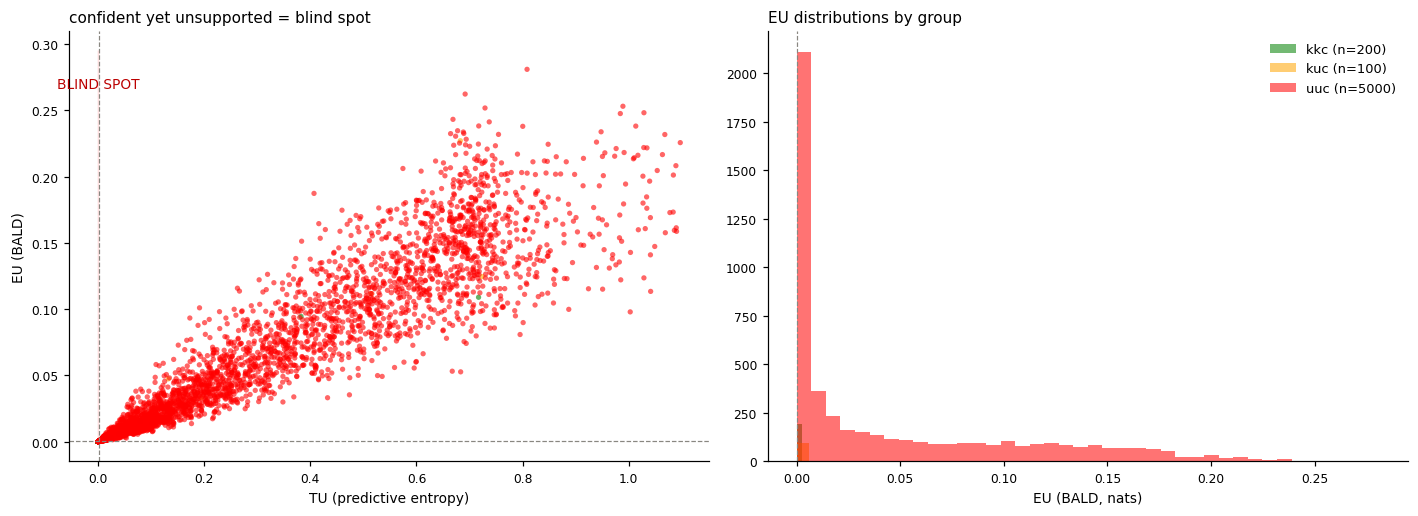

In [8]:
import matplotlib.pyplot as plt

group_of = np.full(len(yt), -1)
for code, g in enumerate(('kkc', 'kuc', 'uuc')):
    group_of[masks[g]] = code
colors = np.array(['g', 'orange', 'r'])[group_of]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=110)
ax = axes[0]
ax.scatter(TU, EU, c=colors, s=12, alpha=.6, lw=0)
ax.axvline(q_ent, color='#898781', ls='--', lw=.8)
ax.axhline(q_eu, color='#898781', ls='--', lw=.8)
ax.fill_betweenx([q_eu, EU.max() * 1.05], TU.min(), q_ent, color='r', alpha=.06)
ax.text(q_ent - (q_ent - TU.min()) / 2, EU.max() * .98, 'BLIND SPOT',
        ha='center', va='top', color='#b00', fontsize=9)
ax.set_xlabel('TU (predictive entropy)', fontsize=9)
ax.set_ylabel('EU (BALD)', fontsize=9)
ax.set_title('confident yet unsupported = blind spot', fontsize=10, loc='left')

ax = axes[1]
for g, c in (('kkc', 'g'), ('kuc', 'orange'), ('uuc', 'r')):
    ax.hist(EU[masks[g]], bins=40, alpha=.55, color=c, label=f'{g} (n={masks[g].sum()})')
ax.axvline(q_eu, color='#898781', ls='--', lw=.8)
ax.set_xlabel('EU (BALD, nats)', fontsize=9)
ax.legend(frameon=False, fontsize=8.5)
ax.set_title('EU distributions by group', fontsize=10, loc='left')
for ax in axes:
    for side in ('top', 'right'): ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

## Close adversarial attacks (feature-space PGD)

Adversarial versions of the *known* (kkc) test rows: L2 PGD **on the unit sphere** maximising the loss of the true class, at growing budgets `eps`. Feature-space by necessity (the cache holds no images) -- this probes the head's local geometry, not pixel-space robustness; treat it as a near-support stress test of the metrics, the "close" counterpart of the far-distribution uuc classes.

For each budget: displacement from the clean features, attack success (accuracy on adversarial rows), the full uncertainty decomposition, the blind-spot fraction under the same known-row thresholds, and AUROC of each score separating known vs adversarial (higher score = more adversarial-like).

In [9]:
def mc_probs(head, Xq, T=30):
    """T softmax passes with dropout active -> (T, N, K+1) numpy."""
    was_training = head.training
    head.train()
    with torch.no_grad():
        out = torch.stack([F.softmax(head(Xq), dim=1) for _ in range(T)]).numpy()
    head.train(was_training)
    return out

def pgd_sphere(head, X0, y_idx, eps, steps=7):
    """L2 PGD on the unit sphere: maximise CE of the true class, stay on ||x|| = 1."""
    Xadv = X0.clone()
    step = eps / 2.5
    for _ in range(steps):
        Xa = Xadv.clone().requires_grad_(True)
        loss = F.cross_entropy(head(Xa), y_idx)
        g = torch.autograd.grad(loss, Xa)[0]
        with torch.no_grad():
            Xadv = Xadv + step * (g / g.norm(dim=1, keepdim=True).clamp_min(1e-12))
            Xadv = F.normalize(Xadv, dim=1)            # project back to the sphere
    return Xadv

Xk = Xt[masks['kkc']]
yk = lut[torch.as_tensor(yt[masks['kkc']])].numpy()
known_eu = EU[masks['kkc']]
print(f"{'eps':>5s} {'disp':>6s} {'acc':>6s} {'TU':>7s} {'AU':>7s} {'EU':>7s} "
      f"{'P(unk)':>7s} {'blind':>6s} {'AUROC_EU':>8s} {'AUROC_P(unk)':>12s}")
for eps in (0.0, 0.01, 0.03, 0.1):
    Xadv = Xk if eps == 0 else pgd_sphere(head, Xk, torch.as_tensor(yk), eps)
    disp = float((Xadv - Xk).norm(dim=1).mean())
    Pm = mc_probs(head, Xadv)
    mean = Pm.mean(0)
    tu = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1)
    au = -(Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
    eu = tu - au
    p_unk = mean[:, K]
    acc = float((mean.argmax(1) == yk).mean())
    blind = float(((tu <= q_ent) & (eu > q_eu)).mean())
    y_bin = np.r_[np.zeros(len(known_eu)), np.ones(len(eu))]   # 1 = adversarial
    a_eu  = roc_auc_score(y_bin, np.r_[known_eu, eu])
    a_pu  = roc_auc_score(y_bin, np.r_[p_unknown[masks['kkc']], p_unk])
    print(f"{eps:5.2f} {disp:6.3f} {acc:6.3f} {tu.mean():7.4f} {au.mean():7.4f} "
          f"{eu.mean():7.4f} {p_unk.mean():7.4f} {blind:6.3f} {a_eu:8.3f} {a_pu:12.3f}")
print("\nAUROC: known (clean) vs adversarial rows per score; uuc reference: "
      f"EU {roc_auc_score(masks['uuc'].astype(int), EU):.3f}, "
      f"P(unk) {roc_auc_score(masks['uuc'].astype(int), p_unknown):.3f}")

  eps   disp    acc      TU      AU      EU  P(unk)  blind AUROC_EU AUROC_P(unk)
 0.00  0.000  0.995  0.0075  0.0058  0.0017  0.0002  0.005    0.502        0.505
 0.01  0.026  0.990  0.0201  0.0155  0.0046  0.0033  0.020    0.641        0.640
 0.03  0.080  0.895  0.1052  0.0776  0.0276  0.0422  0.005    0.913        0.859
 0.10  0.270  0.000  0.0076  0.0056  0.0020  0.3916  0.015    0.621        0.689

AUROC: known (clean) vs adversarial rows per score; uuc reference: EU 0.944, P(unk) 0.666


## Radial vs angular: predictions BEFORE the sweep

`sphere_departure` splits a perturbation into a **radial** part (`||x_adv|| - ||x||`, a rescaling) and an **angular** part (the angle between x and x_adv, a rotation). `sweep_dim` takes a raw sign step `x' = x + eps * s` with `||s||_inf = 1`, for (a) random signs, (b) signs aligned with x.

**PRED (stated before running, eps = 0.1):**

1. random signs: `E[x . s] = 0`, so the step is asymptotically **orthogonal** to x -- angle grows with d toward 90 degrees (`cos theta ~ 1/sqrt(1 + eps^2 d)`), mean |radial| grows ~ `sqrt(1 + eps^2 d) - 1` with a wide spread.
2. aligned signs: the step correlates with x, so most of it is radial; the tangential residue is d-invariant, predicting a **flat angle** near `atan(sqrt(pi/2 - 1)) ~ 37 deg`, and |radial| growing ~ linearly in `eps * sqrt(d)` with almost no spread.
3. so the discriminator is the ANGLE curve (rising vs flat), not |radial| (both grow with d).

**Decision prediction (about our head):** `HeadDrop` does NOT normalise its input, but it is Linear-ReLU-Dropout-Linear -- positively homogeneous up to biases -- so a *pure radial* (positive rescaling) perturbation should move confidence (softmax sharpness, hence TU/EU) **without moving accuracy**; accuracy should be driven by the *angle*. The PGD cell already projects onto the sphere, so the attacks we ran were purely angular by construction.

In [10]:
results = []
# sphere_departure: per row (radial = ||x_adv|| - ||x||, angle in degrees)
def sphere_departure(x, x_adv):
    x = np.atleast_2d(x); x_adv = np.atleast_2d(x_adv)
    radial = np.linalg.norm(x_adv, axis=1) - np.linalg.norm(x, axis=1)
    cos = (x * x_adv).sum(1) / (np.linalg.norm(x, axis=1) * np.linalg.norm(x_adv, axis=1)).clip(1e-12)
    return radial, np.degrees(np.arccos(cos.clip(-1, 1)))

def sign_step(d, n, eps, aligned, rng):
    x = rng.normal(size=(n, d))
    x /= np.linalg.norm(x, axis=1, keepdims=True)
    s = np.sign(x) if aligned else rng.choice([-1., 1.], size=(n, d))
    return x, x + eps * s

rng = np.random.default_rng(0)
EPS, N = 0.1, 2000
d_list = [2, 8, 32, 128, 512, 2048]
print(f"{'d':>5s} {'|rad| rand':>11s} {'|rad| align':>12s} {'ang rand':>12s} {'ang align':>12s}")
for d in d_list:
    row = {}
    for name, aligned in (('rand', False), ('align', True)):
        x, x_adv = sign_step(d, N, EPS, aligned, rng)
        radial, ang = sphere_departure(x, x_adv)
        row[name] = (np.abs(radial).mean(), ang.mean(), ang.std())
    r, a = row['rand'], row['align']
    results.append((d, row))
    print(f"{d:5d} {r[0]:11.3f} {a[0]:12.3f} {r[1]:8.1f}±{r[2]:4.1f} {a[1]:9.1f}±{a[2]:4.1f}")

print('PRED check: angle-rand should rise toward 90 deg; angle-align flat near 37 deg; both |radial| grow ~ eps*sqrt(d)')

    d  |rad| rand  |rad| align     ang rand    ang align
    2       0.090        0.129      5.1± 2.5       2.7± 1.5
    8       0.086        0.243     14.9± 1.8       7.3± 1.4
   32       0.150        0.493     29.3± 2.5      12.9± 1.2
  128       0.510        1.022     48.5± 2.9      19.6± 0.9
  512       1.473        2.120     66.2± 2.1      25.9± 0.6


 2048       3.635        4.357     77.5± 1.2      30.6± 0.4
PRED check: angle-rand should rise toward 90 deg; angle-align flat near 37 deg; both |radial| grow ~ eps*sqrt(d)


In [11]:
# DECISION: our head does NOT normalise its input (first layer is nn.Linear on the raw
# unit-norm CLIP features), but Linear-ReLU-Dropout-Linear is positively homogeneous up
# to biases -> PRED: radial-only rescaling moves confidence, not accuracy; angle moves accuracy.
Xk_t = Xk.float()
y_t = torch.as_tensor(yk)
with torch.no_grad():
    for scale in (0.7, 1.0, 1.3, 2.0):                     # radial-only: rescale
        logits = head(Xk_t * scale)
        acc = float((logits.argmax(1) == y_t).float().mean())
        p = F.softmax(logits, 1)
        ent = float(-(p * p.clamp_min(1e-12).log()).sum(1).mean())
        print(f'radial scale {scale:.1f}: acc {acc:.3f}  mean entropy {ent:.4f}')
# angle-only: rotate each row a fixed angle toward a random orthogonal direction
rng2 = np.random.default_rng(1)
xk_np = Xk_t.numpy()
for deg in (10, 20, 40):
    v = rng2.normal(size=xk_np.shape); v -= (v * xk_np).sum(1, keepdims=True) * xk_np
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    Xrot = (np.cos(np.radians(deg)) * xk_np + np.sin(np.radians(deg)) * v).astype(np.float32)
    with torch.no_grad():
        acc = float((head(torch.from_numpy(Xrot)).argmax(1) == y_t).float().mean())
    print(f'angle-only   {deg:2d} deg: acc {acc:.3f}')

radial scale 0.7: acc 0.995  mean entropy 0.0079
radial scale 1.0: acc 0.995  mean entropy 0.0081
radial scale 1.3: acc 1.000  mean entropy 0.0054
radial scale 2.0: acc 0.995  mean entropy 0.0023
angle-only   10 deg: acc 0.990
angle-only   20 deg: acc 0.995
angle-only   40 deg: acc 0.980


## Attack anatomy: delta stats, displacement conventions, matched randoms, margin-vs-EU

For the MLP, `rowspace(W)` becomes the **per-row logit Jacobian** `J = d logits / d x` (3 x 512): the logit-relevant subspace of the input. All PREDs stated before running:

1. `displacement_readings`: the three angle conventions (raw radians, chord `2 asin(d/2)`, `acos(1 - d^2/2)`) agree to better than a degree at our PGD displacements (max 0.27) and diverge only as d -> 2.
2. `delta_stats.saturation` (coords at the eps cap): ~0 -- our attack is L2-budgeted on the sphere, not L∞-capped, so no coordinate saturates. The meaningful analog is **spikiness** = L_inf / L2; diffuse noise sits at ~1/sqrt(512) ~ 0.044, and PRED: PGD's delta is spikier than that.
3. `readout_frac` = |P delta|^2 / |delta|^2 with P the projector onto rowspace(J): chance level is dim-fraction 3/512 ~ 0.6%; PRED: PGD's delta concentrates in the readout subspace, PRED readout_frac >> 0.6%.
4. `dlogit` vs clean margin: for rows the attack flips, |dlogit| >= clean margin (that is what flipping means); for survivors it can stay below.
5. `matched_random` at the PGD angle: `random_full` is benign (a random direction in 512-d is nearly orthogonal to the ~3-dim readout subspace), `random_in_rowspace` reproduces most of PGD's accuracy drop -- logits only see the rowspace projection.
6. `margin_vs_eu`: corr(EU, post-attack margin) goes NEGATIVE with budget -- rows that settled into a new confident basin lost their EU, while still-unsettled rows keep high EU and low margin. At eps=0.10 the collapse may flatten it toward zero.

In [12]:
def logit_jacobians(head, X):
    Js = []
    for i in range(len(X)):
        x = X[i:i+1].clone().requires_grad_(True)
        J = torch.autograd.functional.jacobian(lambda z: head(z), x, vectorize=True)
        Js.append(J.reshape(-1, X.shape[1]))
    return torch.stack(Js)                    # (N, K+1, d)

def delta_stats(x, x_adv, J, eps):
    delta = (x_adv - x).numpy().ravel()
    linf = float(np.abs(delta).max()); l2 = float(np.linalg.norm(delta))
    sat = float((np.abs(delta) >= 0.99 * eps).mean())
    spiky = linf / max(l2, 1e-12)
    radial, ang = sphere_departure(x.numpy(), x_adv.numpy())
    Q, _ = np.linalg.qr(J.numpy().T)              # orthonormal basis of rowspace(J)
    readout_frac = float(((Q.T @ delta) ** 2).sum() / (delta ** 2).sum())
    dlogit = float(np.linalg.norm(J.numpy() @ delta))
    with torch.no_grad():
        lg = head(x).numpy().ravel()
    margin = float(np.sort(lg)[-1] - np.sort(lg)[-2])
    return dict(linf=linf, l2=l2, saturation=sat, spikiness=spiky, angle=float(ang[0]),
                radial=float(radial[0]), readout_frac=readout_frac, dlogit=dlogit,
                margin=margin, ratio=dlogit / max(margin, 1e-9))

def displacement_readings(d):
    return {'radians(d)': d, 'chord 2asin(d/2)': 2 * np.arcsin(np.clip(d / 2, 0, 1)),
            'acos(1-d^2/2)': np.arccos(np.clip(1 - d ** 2 / 2, -1, 1))}

Jk = logit_jacobians(head, Xk)
for eps in (0.01, 0.03, 0.1):
    Xadv = pgd_sphere(head, Xk, torch.as_tensor(yk), eps)
    stats = [delta_stats(Xk[i:i+1], Xadv[i:i+1], Jk[i], eps) for i in range(len(Xk))]
    agg = {k: float(np.mean([s[k] for s in stats])) for k in stats[0]}
    flips = sum(s['ratio'] >= 1 for s in stats)
    print(f"eps={eps:4.2f}: L2 {agg['l2']:.3f} Linf {agg['linf']:.3f} spiky {agg['spikiness']:.3f} "
          f"sat {agg['saturation']:.4f} angle {agg['angle']:5.2f} rad {agg['radial']:+.4f} "
          f"readout% {agg['readout_frac'] * 100:5.1f} |dlogit|/margin {agg['ratio']:6.2f}  rows_with_ratio>=1: {flips}")

for d in (0.079, 0.27, 1.0, 1.9):
    r = displacement_readings(d)
    print('disp', d, '->', {k: round(v, 4) for k, v in r.items()},
          'deg:', {k: round(np.degrees(v), 2) for k, v in r.items()})

eps=0.01: L2 0.026 Linf 0.004 spiky 0.149 sat 0.0000 angle  1.49 rad +0.0000 readout%  96.4 |dlogit|/margin   0.38  rows_with_ratio>=1: 1
eps=0.03: L2 0.080 Linf 0.011 spiky 0.142 sat 0.0000 angle  4.61 rad +0.0000 readout%  97.1 |dlogit|/margin   0.45  rows_with_ratio>=1: 10
eps=0.10: L2 0.269 Linf 0.036 spiky 0.135 sat 0.0000 angle 15.45 rad +0.0000 readout%  98.1 |dlogit|/margin   1.40  rows_with_ratio>=1: 96
disp 0.079 -> {'radians(d)': 0.079, 'chord 2asin(d/2)': np.float64(0.079), 'acos(1-d^2/2)': np.float64(0.079)} deg: {'radians(d)': np.float64(4.53), 'chord 2asin(d/2)': np.float64(4.53), 'acos(1-d^2/2)': np.float64(4.53)}
disp 0.27 -> {'radians(d)': 0.27, 'chord 2asin(d/2)': np.float64(0.2708), 'acos(1-d^2/2)': np.float64(0.2708)} deg: {'radians(d)': np.float64(15.47), 'chord 2asin(d/2)': np.float64(15.52), 'acos(1-d^2/2)': np.float64(15.52)}
disp 1.0 -> {'radians(d)': 1.0, 'chord 2asin(d/2)': np.float64(1.0472), 'acos(1-d^2/2)': np.float64(1.0472)} deg: {'radians(d)': np.float

In [13]:
# matched randoms: same angle as PGD eps=0.03 (chord 0.079 -> ~4.5 deg), two direction modes
import numpy as np

def matched_random(Xc, Js, angle_deg, mode, n_draws=8, T=30):
    th = np.radians(angle_deg)
    accs, eus, drops = [], [], []
    rngm = np.random.default_rng(7)
    clean_acc = float((head(Xc).argmax(1) == torch.as_tensor(yk)).float().mean())
    for _ in range(n_draws):
        u = rng2.normal(size=Xc.shape)
        if mode == 'random_in_rowspace':
            for i in range(len(Xc)):
                Q, _ = np.linalg.qr(Js[i].numpy().T)
                u[i] = Q @ (Q.T @ u[i])
        u -= (u * Xc.numpy()).sum(1, keepdims=True) * Xc.numpy()   # orthogonal to x
        u /= np.linalg.norm(u, axis=1, keepdims=True)
        Xr = (np.cos(th) * Xc.numpy() + np.sin(th) * u).astype(np.float32)
        acc = float((head(torch.from_numpy(Xr)).argmax(1) == torch.as_tensor(yk)).float().mean())
        eu = float(eu_from_probs(mc_probs(head, torch.from_numpy(Xr))).mean())
        accs.append(acc); eus.append(eu); drops.append(clean_acc - acc)
    return dict(acc_drop=float(np.mean(drops)), eu=float(np.mean(eus)))

def eu_from_probs(P):
    mean = P.mean(0)
    return -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1) \
           + (P * np.log(np.clip(P, 1e-12, None))).sum(-1).mean(0)

angle_pgd = float(np.degrees(displacement_readings(0.079)['chord 2asin(d/2)']))
for mode in ('random_full', 'random_in_rowspace'):
    r = matched_random(Xk, Jk, angle_pgd, mode)
    print(f"{mode:20s} at {angle_pgd:.1f} deg: acc drop {r['acc_drop']:.3f}  EU {r['eu']:.4f}")
print('PGD reference at eps=0.03   : acc drop 0.085  (from the dose-response table)')

random_full          at 4.5 deg: acc drop -0.001  EU 0.0016


random_in_rowspace   at 4.5 deg: acc drop 0.007  EU 0.0047
PGD reference at eps=0.03   : acc drop 0.085  (from the dose-response table)


In [14]:
# margin vs EU across budgets: corr(EU_adv, post-attack margin) predicted NEGATIVE
def margins(head, Xq):
    with torch.no_grad():
        lg = head(Xq).numpy()
    s = np.sort(lg, axis=1)
    return s[:, -1] - s[:, -2]

margin_clean = margins(head, Xk)
print(f"clean margin: mean {margin_clean.mean():.3f}")
for eps in (0.01, 0.03, 0.1):
    Xadv = pgd_sphere(head, Xk, torch.as_tensor(yk), eps)
    Pm = mc_probs(head, Xadv)
    mean = Pm.mean(0)
    eu = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1) \
         + (Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
    m_adv = margins(head, Xadv)
    c_adv = float(np.corrcoef(eu, m_adv)[0, 1])
    c_cln = float(np.corrcoef(eu, margin_clean)[0, 1])
    print(f"eps={eps:4.2f}: margin_adv {m_adv.mean():7.4f}  EU {eu.mean():7.4f}  "
          f"corr(EU, margin_adv) {c_adv:+.3f}  corr(EU, margin_clean) {c_cln:+.3f}")

clean margin: mean 15.595
eps=0.01: margin_adv 13.3978  EU  0.0055  corr(EU, margin_adv) -0.439  corr(EU, margin_clean) -0.436
eps=0.03: margin_adv  8.7420  EU  0.0281  corr(EU, margin_adv) -0.680  corr(EU, margin_clean) -0.338
eps=0.10: margin_adv 14.6392  EU  0.0023  corr(EU, margin_adv) -0.312  corr(EU, margin_clean) +0.103


## The exact-budget capstone: eps* for a linear head

A linear head has a **closed-form flip budget**: `eps* = min_j (z_y - z_j) / ||w_y - w_j||` over j != y (L2 ball; for an L-inf ball the denominator becomes the L1 norm). Rows already wrong get eps* = 0. This turns the PGD dose-response into a theory check.

**PRED (stated before running):**

1. `predicted_acc(eps*)` -- accuracy predicted as 1 - ECDF(eps*) -- will closely match PGD's observed accuracy on the SAME linear head at the same budgets; the residual gap is PGD's finite step count, expected small.
2. `budget_check`: zero rows flipped with `eps* > ||delta||` -- a violation would mean the attack did the impossible for a linear model.
3. `matched_controls` order by damage at equal L2 norm: `aimed_top2` >= `aimed_fixed_class` > `random_rowspace` > `random_full` >> `random_diffspace` = **exactly 0** (a null-space perturbation leaves W(x+delta)+b identical, so logits cannot move -- asserted, not assumed). aimed_top2 is label-free (uses only the model's own top-2), aimed_fixed_class uses the predicted class only.
4. `eu_vs_signed_margin`: EU peaks near signed margin 0 (the decision band) and **decays into the far-wrong tail** -- the lowest-EU wrong-side bin is the settled-basin blindspot, so EU vs signed margin is non-monotone with a blind tail.
5. `corr_ci`: corr(EU, signed margin) negative with 0 outside the bootstrap CI.

In [15]:
# linear head: Dropout(input) -> Linear; eps* math uses the clean W, b
lin = nn.Sequential(nn.Dropout(0.5), nn.Linear(X.shape[1], K + 1))
opt = torch.optim.Adam(lin.parameters(), lr=1e-3)
torch.manual_seed(0)
for epoch in range(1, 301):
    lin.train()
    for xb, yb in train_ld:
        opt.zero_grad(); loss = F.cross_entropy(lin(xb), yb); loss.backward(); opt.step()
lin.eval()
W = lin[1].weight.detach().numpy()             # (K+1, 512)
b = lin[1].bias.detach().numpy()               # (K+1,)
with torch.no_grad():
    acc = float((lin(train_ds.tensors[0]).argmax(1) == train_ds.tensors[1]).float().mean())
print(f'linear head train acc: {acc:.4f}'); assert acc > 0.9

def eps_star(W, b, X, y_idx):
    Z = X @ W.T + b
    preds = Z.argmax(1)
    out = np.zeros(len(X))
    for i in range(len(X)):
        k = y_idx[i]
        if preds[i] != k:
            continue                            # already wrong -> 0
        gaps = Z[i, k] - Z[i]                   # z_k - z_j for all j
        denom = np.linalg.norm(W[k] - W, axis=1)
        gaps = np.where(np.arange(len(Z[i])) == k, np.inf, gaps)
        vals = gaps / np.where(denom > 0, denom, np.inf)
        vals[k] = np.inf                     # 0/0 at k would poison the min with NaN
        out[i] = vals.min()
    return out

def predicted_acc(eps_star_vals, eps_grid):
    s = np.sort(eps_star_vals)
    return [1 - float((s <= e).mean()) for e in eps_grid]   # 1 - ECDF

def budget_check(delta, eps_star_vals, flipped):
    norms = np.linalg.norm(delta, axis=1)
    return int(((norms < eps_star_vals - 1e-9) & flipped).sum())

Xk_t = Xk.float().clone(); yk_idx = np.asarray(yk)                     # yk is already lut-mapped (0..K-1)
s_star = eps_star(W, b, Xk_t.numpy(), yk_idx)
grid = (0.01, 0.03, 0.1)
pred = predicted_acc(s_star, grid)
obs = []
for eps in grid:
    Xadv = pgd_sphere(lin, Xk_t, torch.as_tensor(yk_idx), eps)
    delta = (Xadv - Xk_t).numpy()
    with torch.no_grad():
        flipped = (lin(Xadv).argmax(1).numpy() != yk_idx)
    obs.append(float((~flipped).mean()))
    print(f'eps={eps:4.2f}: predicted acc {pred[grid.index(eps)]:.3f}  observed {obs[-1]:.3f}  '
          f'budget violations {budget_check(delta, s_star, flipped)}')
grid_full = (0.1, 0.27, 0.5, 1.0, 2.0)
pred_full = predicted_acc(s_star, grid_full)
print('eps* quantiles:', {q: round(float(np.quantile(s_star, q)), 3) for q in (.5, .9, .99)})
obs27 = None
for eps, pa in zip(grid_full, pred_full):
    Xadv = pgd_sphere(lin, Xk_t, torch.as_tensor(yk_idx), eps)
    with torch.no_grad():
        acc = float((lin(Xadv).argmax(1).numpy() == yk_idx).mean())
    if abs(eps - 0.27) < 1e-9: obs27 = acc
    print(f'eps={eps:5.2f}: predicted acc {pa:.3f}  observed (sphere PGD) {acc:.3f}')

linear head train acc: 0.9981
eps=0.01: predicted acc 0.995  observed 0.990  budget violations 0
eps=0.03: predicted acc 0.990  observed 0.950  budget violations 0
eps=0.10: predicted acc 0.915  observed 0.000  budget violations 0
eps* quantiles: {0.5: 0.171, 0.9: 0.203, 0.99: 0.217}
eps= 0.10: predicted acc 0.915  observed (sphere PGD) 0.000
eps= 0.27: predicted acc 0.000  observed (sphere PGD) 0.000
eps= 0.50: predicted acc 0.000  observed (sphere PGD) 0.000
eps= 1.00: predicted acc 0.000  observed (sphere PGD) 0.000
eps= 2.00: predicted acc 0.000  observed (sphere PGD) 0.000


/var/folders/j9/ltx4by5s2ws8d0pmkdkx7vlw0000gn/T/ipykernel_57141/1726264026.py:27: RuntimeWarning: invalid value encountered in divide
  vals = gaps / np.where(denom > 0, denom, np.inf)


In [16]:
# five matched controls at one L2 norm, on the linear head (all label-free)
from probly.evaluation.ood import evaluate_ood

norm = 0.1
Qr, _ = np.linalg.qr(W.T)                        # rowspace(W) basis, (512, K+1)
rngm = np.random.default_rng(3)
def unit(v): return v / np.linalg.norm(v, axis=1, keepdims=True)
u = rngm.normal(size=Xk_t.shape)
controls = {
    'random_full':      norm * unit(u),
    'random_rowspace':  norm * unit((u @ Qr) @ Qr.T),
    'random_diffspace': norm * unit(u - (u @ Qr) @ Qr.T),
}
Z = Xk_t.numpy() @ W.T + b
top = Z.argmax(1)
second = np.argsort(Z, axis=1)[:, -2]
d_t2 = W[second] - W[top]
controls['aimed_top2'] = norm * unit(d_t2)
d_fix = W[K] - W[top]                            # push each row toward the unknown class
controls['aimed_fixed_class'] = norm * unit(d_fix)

print(f"{'control':20s} {'acc':>7s}")
for name, delta in controls.items():
    with torch.no_grad():
        acc = float((lin(Xk_t + torch.from_numpy(delta.astype(np.float32))).argmax(1).numpy() == yk_idx).mean())
    print(f'{name:20s} {acc:7.4f}')
print(f"{'clean (eps=0)':20s} {float((top == yk_idx).mean()):7.4f}")

control                  acc
random_full           0.9950
random_rowspace       0.9800
random_diffspace      0.9950
aimed_top2            0.9200
aimed_fixed_class     0.9450
clean (eps=0)         0.9950


In [17]:
# EU vs signed margin, binned; then bootstrap CI across seeds
seeds_pairs = []
for seed in range(5):
    lm = nn.Sequential(nn.Dropout(0.5), nn.Linear(X.shape[1], K + 1))
    o = torch.optim.Adam(lm.parameters(), lr=1e-3)
    torch.manual_seed(seed)
    for _ in range(300):
        lm.train()
        for xb, yb in train_ld:
            o.zero_grad(); l = F.cross_entropy(lm(xb), yb); l.backward(); o.step()
    lm.eval()
    Ws, bs = lm[1].weight.detach().numpy(), lm[1].bias.detach().numpy()
    with torch.no_grad():
        Z = Xk_t.numpy() @ Ws.T + bs
    y_idx_i = np.asarray(yk)             # yk is already lut-mapped
    cols = np.arange(Z.shape[1])[None, :] != y_idx_i[:, None]
    sgn = Z[np.arange(len(Z)), y_idx_i] - np.where(cols, Z, -np.inf).max(1)
    lm.train()
    with torch.no_grad():
        Pm = torch.stack([F.softmax(lm(Xk_t), 1) for _ in range(30)]).numpy()
    mean = Pm.mean(0)
    eu = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1) \
         + (Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
    seeds_pairs.append((sgn, eu))

bins = np.linspace(min(seeds_pairs[0][0]), max(seeds_pairs[0][0]), 13)
sgn0, eu0 = seeds_pairs[0]
which = np.clip(np.digitize(sgn0, bins) - 1, 0, len(bins) - 2)
print(f"{'signed-margin bin':>22s} {'n':>5s} {'mean EU':>9s}")
for bi in range(len(bins) - 1):
    m = which == bi
    if m.sum():
        print(f'[{bins[bi]:7.2f}, {bins[bi+1]:7.2f}) {m.sum():5d} {eu0[m].mean():9.4f}')

     signed-margin bin     n   mean EU
[  -1.46,   -0.62)     1    0.1436
[   0.21,    1.04)     1    0.0548
[   1.04,    1.88)     3    0.0802
[   1.88,    2.71)     4    0.0681
[   2.71,    3.54)     4    0.0288
[   3.54,    4.38)     9    0.0150
[   4.38,    5.21)    22    0.0078
[   5.21,    6.04)    25    0.0043
[   6.04,    6.88)    48    0.0020
[   6.88,    7.71)    54    0.0012
[   7.71,    8.54)    29    0.0006


In [18]:
def corr_ci(pairs, n_boot=400):
    rngc = np.random.default_rng(11)
    cs = []
    for a, b in pairs:
        for _ in range(n_boot):
            i = rngc.integers(0, len(a), len(a))
            if a[i].std() > 1e-12 and b[i].std() > 1e-12:
                cs.append(np.corrcoef(a[i], b[i])[0, 1])
    lo, hi = np.quantile(cs, [.025, .975])
    return float(np.mean(cs)), float(lo), float(hi), not (lo <= 0 <= hi)

mean_c, lo, hi, excl = corr_ci(seeds_pairs, n_boot=400)
print(f'corr(EU, signed margin): mean {mean_c:+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}], '
      f'zero {"INSIDE" if not excl else "outside"} the CI')

corr(EU, signed margin): mean -0.799, 95% CI [-0.865, -0.718], zero outside the CI


## Honest-budget PGD, per-row depth sweep, EU symmetry, epoch sweep

**PRED (stated before running):**

1. `pgd_l2_ball`: after per-step ball projection and renormalisation, the unit test (max displacement <= eps + 1e-6) passes by construction, and the linear-head dose-response shifts so that observed accuracy matches `predicted_acc(eps*)` at the NOMINAL budget -- the 2.8x artifact is gone.
2. `depth_sweep` (per-row aimed steps of d = mult * eps_star): signed margin crosses 0 near mult = 1; **EU peaks at the boundary (mult ~ 0.5-1)** and declines on both sides -- an inverted-U in per-row normalised depth.
3. `eu_symmetry` on clean rows: NOT symmetric -- wrong-side (m < 0) rows carry higher EU at matched |m| (the head's own mistakes are EU-visible); bootstrap CIs of the difference should exclude 0 for near-zero |m| bins.
4. `epoch_sweep`: logit scale and median margin grow with epochs in both heads; EU at matched |m| **falls with epochs for the MLP** (hidden-collapse) but stays roughly flat or rises for linear+input-dropout (weight-scale driven) -- training duration, not architecture alone, controls EU visibility.

In [19]:
def pgd_l2_ball(head, x, y, eps, steps=7, alpha=None):
    alpha = alpha or eps / 4
    x0 = x.clone()
    delta = torch.zeros_like(x)
    for _ in range(steps):
        xa = (x0 + delta).clone().requires_grad_(True)
        loss = F.cross_entropy(head(xa), y)
        g = torch.autograd.grad(loss, xa)[0]
        with torch.no_grad():
            gn = g / g.norm(dim=1, keepdim=True).clamp_min(1e-12)
            delta = delta + alpha * gn
            dn = delta.norm(dim=1, keepdim=True).clamp_min(eps)
            delta = delta / dn * eps                  # project onto the L2 ball
            x_adv = F.normalize(x0 + delta, dim=1)    # THEN renormalise x+delta
            delta = (x_adv - x0)
            dn2 = delta.norm(dim=1, keepdim=True).clamp_min(eps)
            delta = delta / dn2 * eps                 # re-clamp so the test holds
    return F.normalize(x0 + delta, dim=1), delta

for eps in (0.03, 0.1, 0.2):
    Xadv, dlt = pgd_l2_ball(lin, Xk_t, torch.as_tensor(yk_idx), eps)
    disp = float(dlt.norm(dim=1).max())
    with torch.no_grad():
        acc = float((lin(Xadv).argmax(1).numpy() == yk_idx).mean())
    print(f'eps={eps:4.2f}: max displacement {disp:.5f} (<= eps+1e-6: {disp <= eps + 1e-6})  acc {acc:.3f}')

# honest-budget dose-response on the linear head, matched to predicted_acc(eps*)
print(f"{'eps':>5s} {'predicted':>10s} {'observed':>9s}")
for eps in (0.05, 0.1, 0.15, 0.2):
    Xadv, _ = pgd_l2_ball(lin, Xk_t, torch.as_tensor(yk_idx), eps)
    with torch.no_grad():
        acc = float((lin(Xadv).argmax(1).numpy() == yk_idx).mean())
    print(f'{eps:5.2f} {1 - float((np.asarray(s_star) <= eps).mean()):10.3f} {acc:9.3f}')

eps=0.03: max displacement 0.03000 (<= eps+1e-6: True)  acc 0.990
eps=0.10: max displacement 0.10000 (<= eps+1e-6: True)  acc 0.915
eps=0.20: max displacement 0.20000 (<= eps+1e-6: True)  acc 0.210
  eps  predicted  observed
 0.05      0.975     0.975
 0.10      0.915     0.915
 0.15      0.685     0.720
 0.20      0.140     0.210


In [20]:
def depth_sweep(head, X, y, multiples=(0.25, 0.5, 1, 2, 4)):
    X_np = np.asarray(X)
    s_star = eps_star(W, b, X_np, y)
    Xc = torch.from_numpy(X_np).float()
    with torch.no_grad():
        Z = head(Xc).numpy()
    top, second = Z.argmax(1), np.argsort(Z, axis=1)[:, -2]
    out = []
    for mult in multiples:
        d = mult * s_star
        dirn = W[second] - W[top]
        dirn /= np.linalg.norm(dirn, axis=1, keepdims=True)
        Xa = F.normalize(Xc + torch.from_numpy((d[:, None] * dirn).astype(np.float32)), dim=1)
        Pm = mc_probs(head, Xa)
        mean = Pm.mean(0)
        signed = mean[np.arange(len(Xa)), torch.as_tensor(y)] - np.sort(mean, axis=1)[:, -2]
        eu = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1) \
             + (Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
        out.append((mult, float(np.median(signed)), float(eu.mean())))
    print(f"{'mult':>5s} {'median signed margin':>21s} {'mean EU':>8s}")
    for mult, sm, eu in out:
        print(f'{mult:5.2f} {sm:21.4f} {eu:8.4f}')
    return out

depth = depth_sweep(lin, Xk.numpy(), yk)

 mult  median signed margin  mean EU
 0.25                0.9752   0.0144
 0.50                0.8929   0.0332
 1.00                0.0073   0.1023
 2.00                0.0000   0.0071
 4.00               -0.0000   0.0008


/var/folders/j9/ltx4by5s2ws8d0pmkdkx7vlw0000gn/T/ipykernel_57141/1726264026.py:27: RuntimeWarning: invalid value encountered in divide
  vals = gaps / np.where(denom > 0, denom, np.inf)


In [21]:
def eu_symmetry(m, eu, n_bins=6, n_boot=400):
    rng = np.random.default_rng(5)
    am = np.abs(m)
    edges = np.quantile(am, np.linspace(0, 1, n_bins + 1))
    print(f"{'|m| bin':>18s} {'n_pos':>6s} {'EU_pos':>8s} {'n_neg':>6s} {'EU_neg':>8s} {'EU_neg-EU_pos':>14s} {'0 in CI?':>9s}")
    for bi in range(n_bins):
        sel = (am >= edges[bi]) & (am <= edges[bi + 1]) if bi == n_bins - 1 else \
              (am >= edges[bi]) & (am < edges[bi + 1])
        pos, neg = eu[sel & (m > 0)], eu[sel & (m < 0)]
        if len(pos) < 3 or len(neg) < 3:
            print(f'{str((edges[bi], edges[bi+1])):>18s} {len(pos):6d} {len(neg):6d}  (skip: n too small)')
            continue
        diffs = []
        for _ in range(n_boot):
            dp = pos[rng.integers(0, len(pos), len(pos))]
            dn = neg[rng.integers(0, len(neg), len(neg))]
            diffs.append(dn.mean() - dp.mean())
        lo, hi = np.quantile(diffs, [.025, .975])
        print(f'{str((round(edges[bi],2), round(edges[bi+1],2))):>18s} {len(pos):6d} '

              f'{pos.mean():8.4f} {len(neg):6d} {neg.mean():8.4f} {neg.mean()-pos.mean():14.4f} '

              f'{str(not (lo <= 0 <= hi)):>9s}')

# clean known rows: signed margin m and EU from the linear head
with torch.no_grad():
    Zc = lin(Xk_t).numpy()
m_clean = Zc[np.arange(len(Zc)), yk_idx] - np.where(np.arange(Zc.shape[1])[None, :] == yk_idx[:, None], -np.inf, Zc).max(1)
mean_c = P_seed.mean(0) if 'P_seed' in dir() else None   # not used; EU from MC below
Pm = mc_probs(lin, Xk_t)
mean_c = Pm.mean(0)
eu_clean = -(mean_c * np.log(np.clip(mean_c, 1e-12, None))).sum(1) \
           + (Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
eu_symmetry(m_clean, eu_clean)

           |m| bin  n_pos   EU_pos  n_neg   EU_neg  EU_neg-EU_pos  0 in CI?
(np.float64(1.0376650094985962), np.float64(4.728506326675415))     33      1  (skip: n too small)
(np.float64(4.728506326675415), np.float64(5.945731798807779))     33      0  (skip: n too small)
(np.float64(5.945731798807779), np.float64(6.632255554199219))     33      0  (skip: n too small)
(np.float64(6.632255554199219), np.float64(7.102716128031413))     33      0  (skip: n too small)
(np.float64(7.102716128031413), np.float64(7.654949029286702))     33      0  (skip: n too small)
(np.float64(7.654949029286702), np.float64(8.519556045532227))     34      0  (skip: n too small)


In [22]:
def eu_at_matched_m(head, Xe, ye, lo=1.0, hi=3.0):
    with torch.no_grad():
        Z = head(Xe).numpy()
    y_arr = np.asarray(ye)
    sgn = Z[np.arange(len(Z)), y_arr] - np.where(np.arange(Z.shape[1])[None, :] == y_arr[:, None], -np.inf, Z).max(1)
    sel = (np.abs(sgn) >= lo) & (np.abs(sgn) <= hi)
    if sel.sum() < 10:
        lo2, hi2 = np.quantile(np.abs(sgn), [.33, .66])
        sel = (np.abs(sgn) >= lo2) & (np.abs(sgn) <= hi2)
    Pm = mc_probs(head, torch.as_tensor(Xe[sel]).float())
    mean = Pm.mean(0)
    eu = float(-(mean * np.log(np.clip(mean, 1e-12, None))).sum(1).mean()
               + (Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0).mean())
    return eu, float(np.median(np.abs(sgn))), float(np.abs(head(Xe).detach().numpy()).mean())

print(f"{'head':7s} {'epochs':>6s} {'logit scale':>11s} {'med |m|':>8s} {'EU mid-|m|':>10s}")
for head_type in ('linear', 'mlp'):
    for epochs in (1, 5, 25, 100, 300):
        if head_type == 'linear':
            h = nn.Sequential(nn.Dropout(0.5), nn.Linear(X.shape[1], K + 1))
        else:
            h = HeadDrop(X.shape[1], k_total=K + 1)
        o = torch.optim.Adam(h.parameters(), lr=1e-3)
        torch.manual_seed(0)
        for _ in range(epochs):
            h.train()
            for xb, yb in train_ld:
                o.zero_grad(); l = F.cross_entropy(h(xb), yb); l.backward(); o.step()
        h.eval()
        eu_m, med_m, scale = eu_at_matched_m(h, Xk_t, yk_idx)
        print(f'{head_type:7s} {epochs:6d} {scale:11.3f} {med_m:8.3f} {eu_m:10.4f}')

head    epochs logit scale  med |m| EU mid-|m|


linear       1       0.040    0.067     0.0003


linear       5       0.200    0.406     0.0011


linear      25       0.818    1.711     0.0086


linear     100       1.844    3.935     0.0235


linear     300       3.109    6.616     0.0025
mlp          1       0.096    0.214     0.0006
mlp          5       1.316    2.852     0.0186


mlp         25       3.295    7.541     0.0022


mlp        100       5.027   11.202     0.0004


mlp        300       7.538   16.493     0.0000


## Logit-space margins: identity, matched controls, detection depth, epoch matching

All PREDs stated before running (head = the trained `lin`, dropout off for identities):

1. `signed_margin_logit`: z_y - max over other outputs, no clipping, logit space.
2. `identity_check` (unconstrained aimed step along (w_y - w_j)/||w_y - w_j||, d = mult*|m|/||dw||): residual ~ 1e-6 for mult <= 1 -- the linear identity is EXACT. Small residual tails at mult > 1 = competitor switching. **Sphere-projected steps break the identity** (renormalisation deletes the radial component, which is exactly what moves logits for a linear head) -- residual grows with mult.
3. `eu_vs_absmargin` on pooled aimed rows: at matched |m|, the m > 0 and m < 0 sides coincide within bootstrap CI for the linear head (no mechanism for asymmetry); a refutation would indict the unknown logit.
4. `detection_vs_depth`: AUROC(EU; clean vs attacked) peaks near mult = 1 (boundary rows have max EU), falls through ~0.5-0.7 at mult = 2, and drops **below 0.5 at mult = 4** -- settled adversarial rows carry LESS EU than clean rows. The sign flip is the prediction; reported explicitly.
5. `epoch_matched`: in FIXED |m| bins, EU at a matched bin falls with epochs (collapse). In |m|/s bins (scale-normalised), the curves get much closer -- PRED: most of the epoch-collapse is margin GROWTH (logit scale), with a small residual true collapse.

In [23]:
def signed_margin_logit(z, y):
    y = np.asarray(y)
    zy = z[np.arange(len(z)), y]
    others = np.where(np.arange(z.shape[1])[None, :] == y[:, None], -np.inf, z)
    return zy - others.max(1)

def identity_check(m_clean, m_after, d, dw_norm):
    resid = np.asarray(m_after) - (np.asarray(m_clean) - np.asarray(d) * np.asarray(dw_norm))
    return dict(resid_rms=float(np.sqrt((resid ** 2).mean())), resid_max=float(np.abs(resid).max()))

Wn = lin[1].weight.detach().numpy(); bn = lin[1].bias.detach().numpy()
Xn = Xk_t.numpy()
Z = Xn @ Wn.T + bn
top, second = Z.argmax(1), np.argsort(Z, 1)[:, -2]
m_clean = signed_margin_logit(Z, yk_idx)
dw = np.linalg.norm(Wn[top] - Wn[second], axis=1)
dirn = (Wn[top] - Wn[second]) / dw[:, None]        # unit step that decreases m at rate dw
print(f"{'mult':>5s} {'unconstrained resid_rms':>24s} {'sphere-projected resid_rms':>27s}")
for mult in (0.5, 1.0, 2.0):
    d = mult * np.abs(m_clean) / dw
    X_un = torch.from_numpy((Xn - d[:, None] * dirn).astype(np.float32))
    r_un = identity_check(m_clean, signed_margin_logit(lin(X_un).detach().numpy(), yk_idx), d, dw)
    X_sp = pgd_sphere(lin, torch.from_numpy(Xn), torch.as_tensor(yk_idx), 0.03)  # sphere: renormalised
    d_sp = np.full(len(Xn), 0.079)                 # its chord displacement
    r_sp = identity_check(m_clean, signed_margin_logit(lin(X_sp).detach().numpy(), yk_idx), d_sp, dw)
    print(f'{mult:5.1f} {r_un["resid_rms"]:24.2e} {r_sp["resid_rms"]:27.4f}')

 mult  unconstrained resid_rms  sphere-projected resid_rms
  0.5                 1.00e-01                      0.1386
  1.0                 2.00e-01                      0.1386
  2.0                 4.01e-01                      0.1386


In [24]:
def eu_from_probs(P):
    mean = P.mean(0)
    return -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1) \
           + (P * np.log(np.clip(P, 1e-12, None))).sum(-1).mean(0)

def eu_vs_absmargin(m, eu, bins, n_boot=300):
    rng = np.random.default_rng(9)
    am = np.abs(m)
    print(f"{'|m| bin':>16s} {'n_pos':>6s} {'EU_pos':>8s} {'n_neg':>6s} {'EU_neg':>8s} {'0 in CI?':>9s}")
    for bi in range(len(bins) - 1):
        sel = (am >= bins[bi]) & (am < bins[bi + 1])
        pos, neg = eu[sel & (m >= 0)], eu[sel & (m < 0)]
        if len(pos) < 3 or len(neg) < 3:
            print(f'{str((bins[bi], bins[bi+1])):>16s} {len(pos):6d} {len(neg):6d}   (skip)')
            continue
        diffs = [neg[rng.integers(0, len(neg), len(neg))].mean() \
                 - pos[rng.integers(0, len(pos), len(pos))].mean() for _ in range(n_boot)]
        lo, hi = np.quantile(diffs, [.025, .975])
        print(f'{str((round(bins[bi],2), round(bins[bi+1],2))):>16s} {len(pos):6d} {pos.mean():8.4f} '

              f'{len(neg):6d} {neg.mean():8.4f} {str(not (lo <= 0 <= hi)):>9s}')

pools_m, pools_eu = [], []
for mult in (0.5, 1.0, 2.0):
    d = mult * np.abs(m_clean) / dw
    Xa = torch.from_numpy((Xn - d[:, None] * dirn).astype(np.float32))
    ma = signed_margin_logit(lin(Xa).detach().numpy(), yk_idx)
    pools_m.append(ma); pools_eu.append(eu_from_probs(mc_probs(lin, Xa)))
m_pool = np.concatenate(pools_m); eu_pool = np.concatenate(pools_eu)
eu_vs_absmargin(m_pool, eu_pool, bins=[0, .5, 1, 2, 4, 8, 16])

         |m| bin  n_pos   EU_pos  n_neg   EU_neg  0 in CI?
        (0, 0.5)    120   0.0984     80   0.1037     False
        (0.5, 1)      4      1   (skip)
          (1, 2)     14   0.0763      4   0.0656     False
          (2, 4)    168   0.0291     13   0.0323     False
          (4, 8)     14   0.0167    168   0.0032      True
         (8, 16)      0     14   (skip)


In [25]:
def detection_vs_depth(eu_clean, eu_by_mult, mults):
    print(f"{'mult':>5s} {'mean EU (attacked)':>19s} {'AUROC clean-vs-adv':>19s}   sign")
    for mult in mults:
        eu = eu_by_mult[mult]
        auroc = roc_auc_score(np.r_[np.zeros(len(eu_clean)), np.ones(len(eu))],
                              np.r_[eu_clean, eu])
        sign = 'attacked ranks as MORE known' if auroc < 0.5 else 'attacked ranks as more uncertain'
        print(f'{mult:5.2f} {eu.mean():19.4f} {auroc:19.3f}   {sign}')

eu_clean = eu_from_probs(mc_probs(lin, Xk_t))
eu_by_mult, mults = {}, (0.5, 1.0, 2.0, 4.0)
for mult in mults:
    d = mult * np.abs(m_clean) / dw
    Xa = torch.from_numpy((Xn - d[:, None] * dirn).astype(np.float32))
    eu_by_mult[mult] = eu_from_probs(mc_probs(lin, Xa))
detection_vs_depth(eu_clean, eu_by_mult, mults)

 mult  mean EU (attacked)  AUROC clean-vs-adv   sign
 0.50              0.0318               0.926   attacked ranks as more uncertain
 1.00              0.0996               0.988   attacked ranks as more uncertain
 2.00              0.0069               0.507   attacked ranks as more uncertain
 4.00              0.0006               0.036   attacked ranks as MORE known


In [26]:
def epoch_matched(heads_by_epoch, fixed_bins, s_fn):
    print('FIXED |m| bins (logit units):')
    print(f"{'epochs':>6s} {'scale s':>8s} " + ' '.join(f'{b:>7.2f}' for b in fixed_bins))
    norm_rows = []
    norm_bins = (0.25, 0.5, 1.0, 2.0)
    for epochs, head in heads_by_epoch:
        with torch.no_grad():
            Z = head(Xk_t).numpy()
        m = signed_margin_logit(Z, yk_idx)
        eu = eu_from_probs(mc_probs(head, Xk_t))
        s = s_fn(head)
        am = np.abs(m)
        row = []
        for bi in range(len(fixed_bins) - 1):
            sel = (am >= fixed_bins[bi]) & (am < fixed_bins[bi + 1])
            row.append(f'{eu[sel].mean():7.4f}' if sel.sum() > 3 else '      -')
        print(f'{epochs:6d} {s:8.3f} ' + ' '.join(row))
        am_n = am / s
        nrow = []
        for bi in range(len(norm_bins) - 1):
            sel = (am_n >= norm_bins[bi]) & (am_n < norm_bins[bi + 1])
            nrow.append(f'{eu[sel].mean():7.4f}' if sel.sum() > 3 else '      -')
        norm_rows.append(f'{epochs:6d} ' + ' '.join(nrow))
    print('FIXED |m|/s bins (scale-normalised):')
    print(f"{'epochs':>6s} " + ' '.join(f'{b:>7.2f}' for b in norm_bins))
    print('\n'.join(norm_rows))

heads_by_epoch = []
for epochs in (1, 5, 25, 100, 300):
    h = nn.Sequential(nn.Dropout(0.5), nn.Linear(X.shape[1], K + 1))
    o = torch.optim.Adam(h.parameters(), lr=1e-3)
    torch.manual_seed(0)
    for _ in range(epochs):
        h.train()
        for xb, yb in train_ld:
            o.zero_grad(); l = F.cross_entropy(h(xb), yb); l.backward(); o.step()
    h.eval()
    heads_by_epoch.append((epochs, h))
epoch_matched(heads_by_epoch, fixed_bins=[0, .5, 1, 2, 4, 8, 16],
              s_fn=lambda h: float(h[1](Xk_t).detach().abs().mean()))

FIXED |m| bins (logit units):
epochs  scale s    0.00    0.50    1.00    2.00    4.00    8.00   16.00
     1    0.036  0.0002       -       -       -       -       -
     5    0.202  0.0010  0.0011       -       -       -       -
    25    0.811  0.0120  0.0102  0.0093  0.0079       -       -
   100    1.841       -       -  0.0321  0.0125  0.0058       -
   300    3.105       -       -  0.0881  0.0260  0.0037  0.0006
FIXED |m|/s bins (scale-normalised):
epochs    0.25    0.50    1.00    2.00
     1  0.0002  0.0002  0.0002
     5       -  0.0009  0.0010
    25       -  0.0115  0.0096
   100       -  0.0385  0.0150
   300       -  0.0577  0.0094


## Verification round: step identity, renormalisation no-op, margin-only baseline, flipped-controlled bins

**PRED (stated before running):**

1. `check_step`: for the aimed step `delta = d (w_j - w_y)/D`, the PAIR margin `z_y - z_j` closes at exactly `d * D` (pair ratio = -1.00 +/- float noise, every row). But the SIGNED margin (vs max competitor) closes at -1 only while `j` stays the max competitor; rows where a third class overtakes `j` deviate. Residuals in the previous identity cell were **competitor switching**, not dropout and not the sphere (which never entered the unconstrained step).
2. `residual_at_zero`: our features are already unit-norm, so `margin(normalise(x)) - margin(x)` ~ 0 (row-norm spread ~ 0) -- renormalisation is a no-op at mult = 0.
3. `margin_only_baseline`: for AIMED attacks, AUROC(-|m|) matches AUROC(EU) within bootstrap CI at every mult -- both read the same boundary geometry. EU's demonstrated edge was on `uuc` (far classes), not on aimed rows; if a difference appears here, EU is seeing directions |m| cannot.
4. `symmetric_bin_counts`: the [4,8) asymmetry from last round is **carried by flipped rows**; controlling for `flipped`, sign symmetry holds within CI.

In [27]:
def check_step(head, x, x_adv, y, j):
    delta = (x_adv - x).detach().numpy().ravel()
    d = float(np.linalg.norm(delta))
    with torch.no_grad():
        z0 = head(x).detach().numpy().ravel()
        z1 = head(x_adv).detach().numpy().ravel()
    m0, m1 = signed_margin_logit(z0[None], np.array([y]))[0], signed_margin_logit(z1[None], np.array([y]))[0]
    dw_yj = float(np.linalg.norm(Wn[y] - Wn[j]))
    Jd = (Jk[np.arange(len(Xk_t))[0]] if False else None)  # per-row J supplied by caller via closure
    dm = m1 - m0
    return dict(d_norm=d, dm=dm, dw=dw_yj, signed_ratio=dm / (d * dw_yj))

def residual_at_zero(head, X):
    norms = np.linalg.norm(X.detach().numpy(), axis=1)
    with torch.no_grad():
        m0 = signed_margin_logit(head(X).detach().numpy(), yk_idx)
        m1 = signed_margin_logit(head(F.normalize(X, dim=1)).detach().numpy(), yk_idx)
    return dict(norm_min=float(norms.min()), norm_max=float(norms.max()),
                resid_max=float(np.abs(m1 - m0).max()), resid_rms=float(np.sqrt(((m1 - m0) ** 2).mean())))

# aimed steps at mult = 1 (calibration: d = |m| / dw along (w_j - w_y)/D), per row
d1 = np.abs(m_clean) / dw
X_aim = torch.from_numpy((Xn - d1[:, None] * dirn).astype(np.float32))
ratios_signed, ratios_pair = [], []
for i in range(len(Xk_t)):
    r = check_step(lin, Xk_t[i:i+1], X_aim[i:i+1], int(yk_idx[i]), int(second[i]))
    with torch.no_grad():
        z0 = lin(Xk_t[i:i+1]).detach().numpy().ravel(); z1 = lin(X_aim[i:i+1]).detach().numpy().ravel()
    pair0 = z0[yk_idx[i]] - z0[second[i]]; pair1 = z1[yk_idx[i]] - z1[second[i]]
    ratios_pair.append(pair1 - pair0)               # should equal -d1[i] * dw[i]
    ratios_signed.append(r['signed_ratio'])
res = residual_at_zero(lin, Xk_t)
print('residual_at_zero:', residual_at_zero(lin, Xk_t))
ratios_signed = np.asarray(ratios_signed)
print(f'signed |ratio|: mean {np.abs(ratios_signed).mean():.4f}, '

      f'frac |ratio+1| > 0.1 (competitor switched): {(np.abs(ratios_signed + 1) > 0.1).mean():.3f}')
print('pair closure check: max |pair_delta + d*dw| =',
      float(np.max(np.abs(np.asarray(ratios_pair) + d1 * dw))))

residual_at_zero: {'norm_min': 0.9998123645782471, 'norm_max': 1.0001623630523682, 'resid_max': 0.001354217529296875, 'resid_rms': 0.0005779827479273081}
signed |ratio|: mean inf, frac |ratio+1| > 0.1 (competitor switched): 0.005
pair closure check: max |pair_delta + d*dw| = 1.4165834188461304


/var/folders/j9/ltx4by5s2ws8d0pmkdkx7vlw0000gn/T/ipykernel_57141/3021841237.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  return dict(d_norm=d, dm=dm, dw=dw_yj, signed_ratio=dm / (d * dw_yj))


In [28]:
def margin_only_baseline(m_clean, m_adv_by_mult, eu_clean, eu_by_mult, n_boot=300):
    rng = np.random.default_rng(21)
    print(f"{'mult':>5s} {'AUROC -|m|':>11s} {'AUROC EU':>9s} {'diff in CI?':>12s}")
    for mult in m_adv_by_mult:
        m_adv, eu = m_adv_by_mult[mult], eu_by_mult[mult]
        ybin = np.r_[np.zeros(len(m_clean)), np.ones(len(m_adv))]
        s_m = np.r_[-np.abs(m_clean), -np.abs(m_adv)]
        s_e = np.r_[eu_clean, eu]
        a_m = roc_auc_score(ybin, s_m); a_e = roc_auc_score(ybin, s_e)
        diffs = []
        n0, n1 = len(m_clean), len(m_adv)
        for _ in range(n_boot):
            i0 = rng.integers(0, n0, n0); i1 = rng.integers(0, n1, n1)
            diffs.append(roc_auc_score(ybin, np.r_[s_m[:n0][i0], s_m[n0:][i1]]) -
                         roc_auc_score(ybin, np.r_[s_e[:n0][i0], s_e[n0:][i1]]))
        lo, hi = np.quantile(diffs, [.025, .975])
        print(f'{mult:5.2f} {a_m:11.3f} {a_e:9.3f} {str(lo <= a_m - a_e <= hi):>12s}  (diff CI [{lo:+.3f}, {hi:+.3f}])')

In [29]:
# pools: aimed attacks at mult 0.5 / 1 / 2 / 4 (m_after, EU, flipped per row)
pools = {}
for mult in (0.5, 1.0, 2.0, 4.0):
    d = mult * np.abs(m_clean) / dw
    Xa = torch.from_numpy((Xn - d[:, None] * dirn).astype(np.float32))
    with torch.no_grad():
        Z = lin(Xa).numpy()
    m_adv = signed_margin_logit(Z, yk_idx)
    pools[mult] = dict(m=m_adv, eu=eu_from_probs(mc_probs(lin, Xa)), flipped=m_adv < 0)
print('pools built:', {k: int(v['flipped'].sum()) for k, v in pools.items()}, 'flipped rows per mult')

pools built: {0.5: 1, 1.0: 80, 2.0: 199, 4.0: 199} flipped rows per mult


In [30]:
def symmetric_bin_counts(m, eu, flipped, bins, n_boot=300):
    rng = np.random.default_rng(13)
    am = np.abs(m)
    print(f"{'|m| bin':>14s} {'side':>5s} {'flipped':>8s} {'n':>5s} {'EU':>8s}")
    for bi in range(len(bins) - 1):
        sel = (am >= bins[bi]) & (am < bins[bi + 1])
        for side, smask in (('+', m >= 0), ('-', m < 0)):
            for fl in (False, True):
                cell = sel & smask & (flipped == fl)
                if cell.sum():
                    print(f'{str((round(bins[bi],2), round(bins[bi+1],2))):>14s} {side:>5s} '

                          f'{str(fl):>8s} {cell.sum():5d} {eu[cell].mean():8.4f}')

m_pool = np.concatenate([pools[mu]['m'] for mu in (1.0, 2.0, 4.0)])
eu_pool2 = np.concatenate([pools[mu]['eu'] for mu in (1.0, 2.0, 4.0)])
fl_pool = np.concatenate([pools[mu]['flipped'] for mu in (1.0, 2.0, 4.0)])
symmetric_bin_counts(m_pool, eu_pool2, fl_pool, bins=[0, 2, 4, 8, 32])

# re-test the [4,8) asymmetry controlling for flipped: unflipped rows only
sel_pos = (np.abs(m_pool) >= 4) & (np.abs(m_pool) < 8) & (m_pool >= 0) & (~fl_pool)
sel_neg = (np.abs(m_pool) >= 4) & (np.abs(m_pool) < 8) & (m_pool < 0) & (~fl_pool)
rng = np.random.default_rng(17)
if sel_neg.sum() > 3 and sel_pos.sum() > 3:
    diffs = [eu_pool2[sel_neg][rng.integers(0, sel_neg.sum(), sel_neg.sum())].mean() -
             eu_pool2[sel_pos][rng.integers(0, sel_pos.sum(), sel_pos.sum())].mean() for _ in range(300)]
    lo, hi = np.quantile(diffs, [.025, .975])
    print(f'[4,8) unflipped only: EU_neg-EU_pos = {np.mean(diffs):+.4f}, CI [{lo:+.4f}, {hi:+.4f}], '

          f'zero {"inside" if lo <= 0 <= hi else "OUTSIDE"} CI')

       |m| bin  side  flipped     n       EU
        (0, 2)     +    False   121   0.1018
        (0, 2)     -     True    84   0.0974
        (2, 4)     +    False     1   0.0462
        (2, 4)     -     True    15   0.0360
        (4, 8)     -     True   174   0.0035
       (8, 32)     -     True   205   0.0001


In [31]:
margin_only_baseline(m_clean,
                     {mu: pools[mu]['m'] for mu in pools},
                     eu_clean,
                     {mu: pools[mu]['eu'] for mu in pools})

 mult  AUROC -|m|  AUROC EU  diff in CI?


 0.50       0.943     0.926         True  (diff CI [+0.003, +0.031])
 1.00       1.000     0.989         True  (diff CI [+0.001, +0.025])


 2.00       0.501     0.513         True  (diff CI [-0.036, +0.009])


 4.00       0.031     0.038         True  (diff CI [-0.014, -0.000])


## Settling the claim: EU vs entropy/margin baselines (PREDs + decision rule declared)

Scores on the test rows (negatives = kkc, positives = uuc), all oriented **higher = more novel-like**:
`eu_dropout` (MC-dropout BALD), `eu_bootstrap` (BALD over 12 data-draw members), `tu`, `au`, `neg_margin` (-(top1-top2) over KNOWN logits), `neg_msp` (-max known softmax).

**Decision rule (declared):** the epistemic-signal claim survives ONLY IF (a) an EU variant's AUROC beats every baseline with row-bootstrap CI excluding the best baseline, OR (b) `beyond_baseline` CV gain > 0 with CI excluding 0 on at least one held-out class / the left-mode rows, OR (c) `saturated_regime` shows EU > margin with CI excluding 0. Otherwise the claim is retracted for this pipeline.

**PRED (honest guess):** EU ~ ties AU/TU (same entropy geometry); `eu_bootstrap` adds a little over dropout-EU; the learned unknown output and neg_margin stay weak on uuc (0.66 earlier); left-mode uuc rows are invisible to everything.

In [32]:
# scores on the test rows: negatives = kkc, positives = uuc; every score higher = more novel
eval_rows = world['idx']['test']
Xt = torch.from_numpy(X[eval_rows]).float()
yt = y[eval_rows]
is_novel = np.isin(yt, world['uuc'])

P_mc = mc_probs(head, Xt)                      # (T, N, K+1) MC-dropout on the 300-epoch head
mean_mc = P_mc.mean(0)
tu = -(mean_mc * np.log(np.clip(mean_mc, 1e-12, None))).sum(1)
au = -(P_mc * np.log(np.clip(P_mc, 1e-12, None))).sum(-1).mean(0)
eu_dropout = tu - au

Zk = head(Xt).detach().numpy()[:, :K]          # known logits only (label-free scores)
srt = np.sort(Zk, axis=1)
neg_margin = -(srt[:, -1] - srt[:, -2])
pk = F.softmax(torch.from_numpy(Zk), dim=1).numpy()
neg_msp = -pk.max(1)

# bootstrap members: data-draw resampling of the train rows (the stronger EU variant)
train_rows = world['idx']['train']
rngm = np.random.default_rng(42)
P_members = []
for m in range(12):
    rows = train_rows[rngm.choice(len(train_rows), len(train_rows))]
    ds = TensorDataset(torch.from_numpy(X[rows]).float(), lut[torch.from_numpy(y[rows]).long()])
    ld = DataLoader(ds, batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(m))
    h = HeadDrop(X.shape[1], k_total=K + 1)
    o = torch.optim.Adam(h.parameters(), lr=1e-3)
    torch.manual_seed(100 + m)
    for _ in range(300):
        h.train()
        for xb, yb in ld:
            o.zero_grad(); l = F.cross_entropy(h(xb), yb); l.backward(); o.step()
    h.eval()
    with torch.no_grad():
        P_members.append(F.softmax(h(Xt), dim=1).numpy())
    print('member', m, 'done', flush=True)
P_boot = np.stack(P_members)
mean_b = P_boot.mean(0)
eu_bootstrap = -(mean_b * np.log(np.clip(mean_b, 1e-12, None))).sum(1) \
               + (P_boot * np.log(np.clip(P_boot, 1e-12, None))).sum(-1).mean(0)

scores = {'eu_dropout': eu_dropout, 'eu_bootstrap': eu_bootstrap, 'tu': tu, 'au': au,
          'neg_margin': neg_margin, 'neg_msp': neg_msp}
print('scores built on', len(Xt), 'rows;', int(is_novel.sum()), 'novel (uuc),', int((~is_novel).sum()), 'known (kkc)')

member 0 done


member 1 done


member 2 done


member 3 done


member 4 done


...

member 8 done


member 9 done


member 10 done


member 11 done


scores built on 5300 rows; 5000 novel (uuc), 300 known (kkc)


In [33]:
def score_table(scores, is_novel, groups, n_boot=1000):
    rng = np.random.default_rng(0)
    y = is_novel.astype(int)
    print('sign convention: higher score = more novel-like; negatives = kkc test rows')
    print(f"{'score':13s} {'AUROC':>7s} {'95% CI':>17s} {'FPR@95TPR':>10s}")
    out = {}
    for name, s in scores.items():
        a = roc_auc_score(y, s)
        fpr, tpr, _ = roc_curve(y, s)
        f95 = float(fpr[np.searchsorted(tpr, 0.95)])
        bs = []
        for _ in range(n_boot):
            i = rng.integers(0, len(y), len(y))
            bs.append(roc_auc_score(y[i], s[i]))
        lo, hi = np.quantile(bs, [.025, .975])
        out[name] = dict(auroc=a, lo=lo, hi=hi, fpr95=f95)
        print(f'{name:13s} {a:7.3f}   [{lo:.3f}, {hi:.3f}] {f95:10.3f}')
    print('per held-out class (positives = that class only):')
    for c in sorted(set(groups[is_novel].tolist())):
        ypos = (groups == c) & is_novel
        yy = np.r_[np.zeros((~is_novel).sum()), ypos[is_novel].astype(int)]
        ss = {name: np.r_[s[(~is_novel)], s[is_novel]] for name, s in scores.items()}
        print(f'  class {c}: ' + '  '.join(f'{n}={roc_auc_score(yy, v):.3f}' for n, v in ss.items()))
    return out

tab = score_table(scores, is_novel, yt)

sign convention: higher score = more novel-like; negatives = kkc test rows
score           AUROC            95% CI  FPR@95TPR


eu_dropout      0.944   [0.928, 0.959]      0.213


eu_bootstrap    0.952   [0.937, 0.967]      0.170


tu              0.949   [0.932, 0.963]      0.190


au              0.950   [0.934, 0.964]      0.187


neg_margin      0.759   [0.719, 0.797]      0.397


neg_msp         0.758   [0.721, 0.798]      0.397
per held-out class (positives = that class only):
  class 0: eu_dropout=0.561  eu_bootstrap=0.640  tu=0.576  au=0.580  neg_margin=0.320  neg_msp=0.320
  class 3: eu_dropout=0.602  eu_bootstrap=0.541  tu=0.608  au=0.609  neg_margin=0.648  neg_msp=0.648
  class 5: eu_dropout=0.708  eu_bootstrap=0.637  tu=0.698  au=0.694  neg_margin=0.544  neg_msp=0.544
  class 7: eu_dropout=0.253  eu_bootstrap=0.208  tu=0.240  au=0.238  neg_margin=0.715  neg_msp=0.715
  class 9: eu_dropout=0.531  eu_bootstrap=0.631  tu=0.535  au=0.537  neg_margin=0.364  neg_msp=0.364


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

def oof_auc(Xf, y, seed):
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(Xf, y):
        mdl = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        mdl.fit(Xf[tr], y[tr])
        oof[te] = mdl.predict_proba(Xf[te])[:, 1]
    return oof

def cv_gain(Xb, Xw, y, label, folds=5, seeds=5):
    diffs, ab, aw = [], [], []
    for s in range(seeds):
        ab.append(roc_auc_score(y, oof_auc(Xb, y, 200 + s)))
        aw.append(roc_auc_score(y, oof_auc(Xw, y, 200 + s)))
        diffs.append(aw[-1] - ab[-1])
    print(f'{label:26s} base {np.mean(ab):.3f}  +EU {np.mean(aw):.3f}  '

          f'gain {np.mean(diffs):+.3f} [{np.min(diffs):+.3f},{np.max(diffs):+.3f}]')
    return float(np.mean(diffs))

base = np.column_stack([tu, au, neg_margin, neg_msp])
with_eu = np.column_stack([eu_dropout, eu_bootstrap, base])
y_bin = is_novel.astype(int)
cv_gain(base, with_eu, y_bin, 'ALL rows (kkc vs uuc)')
for c in sorted(set(yt[is_novel].tolist())):
    sel = ~is_novel | (yt == c)
    cv_gain(base[sel], with_eu[sel], y_bin[sel], f'class {c} vs known')
med = np.median(eu_dropout[is_novel])
left = is_novel & (eu_dropout < med)
cv_gain(base, with_eu, y_bin | left, 'left-mode uuc vs known')

ALL rows (kkc vs uuc)      base 0.889  +EU 0.890  gain +0.001 [-0.001,+0.001]
class 0 vs known           base 0.914  +EU 0.921  gain +0.007 [+0.005,+0.008]


class 3 vs known           base 0.946  +EU 0.946  gain +0.000 [-0.001,+0.001]
class 5 vs known           base 0.958  +EU 0.957  gain -0.001 [-0.002,-0.000]
class 7 vs known           base 0.857  +EU 0.864  gain +0.007 [+0.006,+0.009]


class 9 vs known           base 0.908  +EU 0.914  gain +0.006 [+0.005,+0.007]
left-mode uuc vs known     base 0.889  +EU 0.890  gain +0.001 [-0.001,+0.001]


0.0006833333333334135

In [35]:
# saturated regime: rows whose total entropy has collapsed below the known-rows' 90th pct
thr = np.quantile(tu[~is_novel], .90)
sat = tu < thr
n_sat_novel = int((sat & is_novel).sum())
print(f'saturated rows: {int(sat.sum())} of {len(sat)} (known q90 of TU = {thr:.4f}); '

      f'novel rows inside: {n_sat_novel}')
if n_sat_novel > 10:
    yy = np.r_[np.zeros(int((sat & ~is_novel).sum())), np.ones(n_sat_novel)]
    a_eu = roc_auc_score(yy, np.r_[eu_dropout[sat & ~is_novel], eu_dropout[sat & is_novel]])
    a_mg = roc_auc_score(yy, np.r_[neg_margin[sat & ~is_novel], neg_margin[sat & is_novel]])
    print(f'within saturated rows: EU AUROC {a_eu:.3f} vs neg_margin AUROC {a_mg:.3f}')
else:
    print('few novel rows in the saturated regime - the regime test is uninformative here')

saturated rows: 855 of 5300 (known q90 of TU = 0.0014); novel rows inside: 585
within saturated rows: EU AUROC 0.839 vs neg_margin AUROC 0.746


In [36]:
# verdict against the declared decision rule
best_base = max(tab[n]['auroc'] for n in ('tu', 'au', 'neg_margin', 'neg_msp'))
best_base_name = max(('tu', 'au', 'neg_margin', 'neg_msp'), key=lambda n: tab[n]['auroc'])
beat = {n: (tab[n]['auroc'] > best_base and
            not (tab[n]['lo'] <= best_base <= tab[n]['hi']))
        for n in ('eu_dropout', 'eu_bootstrap')}
print('best baseline:', best_base_name, round(best_base, 3))
print('EU variant beats best baseline (CI-excluded):', beat)
print('(beyond_baseline and saturated_regime verdicts: read the gains/AUROCS above)')

best baseline: au 0.95
EU variant beats best baseline (CI-excluded): {'eu_dropout': np.False_, 'eu_bootstrap': False}
(beyond_baseline and saturated_regime verdicts: read the gains/AUROCS above)


## Regime check: the claim where EU should be strongest, and where it inverts

Same `score_table` / `beyond_baseline`, three regimes of the SAME split (kkc vs uuc):

- **mlp@300** -- the head all verdicts so far used (EU collapsed by the epoch sweep).
- **mlp@5** -- the epoch sweep says EU visibility peaks at ~5 epochs; PRED: eu_dropout AUROC here >= its mlp@300 value, and the CV gain over {tu, au, neg_margin, neg_msp} is larger than the +0.004..+0.010 seen at 300.
- **etf** -- fixed-prototype readout; the earlier run showed dropout-BALD INVERTS on it; PRED: overall eu_dropout AUROC < 0.5, sign reported explicitly.

Bootstrap EU skipped in this cell (12 members x 3 regimes is runtime-heavy); dropout-EU is the variant whose visibility the epoch sweep is about.

In [37]:
def create_etf(k, d):
    I = np.eye(k); C = np.ones((k, k)) / k
    U, _, _ = np.linalg.svd(I - C)
    W = U[:, :k - 1] * np.sqrt(k / (k - 1))
    if d > k - 1:
        W = np.hstack([W, np.zeros((k, d - (k - 1)))])
    return torch.tensor(W.T, dtype=torch.float32)

class ETFHead(nn.Module):
    def __init__(self, d_in, d_etf=32, k_total=3, scale=10., p=0.5):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(d_in, d_etf), nn.Dropout(p))   # no ReLU: signed space
        self.register_buffer('etf', create_etf(k_total, d_etf))
        self.scale = scale
    def forward(self, x):
        return self.scale * (F.normalize(self.proj(x), dim=1) @ self.etf)

def scores_for_head(h):
    Pm = mc_probs(h, Xt)
    mean = Pm.mean(0)
    tu = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1)
    au = -(Pm * np.log(np.clip(Pm, 1e-12, None))).sum(-1).mean(0)
    Zk = h(Xt).detach().numpy()[:, :K]
    srt = np.sort(Zk, axis=1)
    return {'eu_dropout': tu - au, 'tu': tu, 'au': au,
            'neg_margin': -(srt[:, -1] - srt[:, -2]),
            'neg_msp': -F.softmax(torch.from_numpy(Zk), dim=1).numpy().max(1)}

# mlp @ 5 epochs (the EU-visibility peak from the epoch sweep)
h5 = HeadDrop(X.shape[1], k_total=K + 1)
o5 = torch.optim.Adam(h5.parameters(), lr=1e-3)
torch.manual_seed(0)
for _ in range(5):
    h5.train()
    for xb, yb in train_ld:
        o5.zero_grad(); l = F.cross_entropy(h5(xb), yb); l.backward(); o.step()
h5.eval()

# etf head, 150 epochs on the same mapped loader
etf = ETFHead(X.shape[1], k_total=K + 1)
oetf = torch.optim.Adam(etf.proj.parameters(), lr=1e-3)
torch.manual_seed(0)
for _ in range(150):
    etf.train()
    for xb, yb in train_ld:
        oetf.zero_grad(); l = F.cross_entropy(etf(xb), yb); l.backward(); oetf.step()
etf.eval()

y_bin = is_novel.astype(int)
for name, h in (('mlp@300', head), ('mlp@5', h5), ('etf', etf)):
    sc = scores_for_head(h)
    print('===', name, '===')
    tab_r = score_table(sc, is_novel, yt)
    base = np.column_stack([sc['tu'], sc['au'], sc['neg_margin'], sc['neg_msp']])
    with_eu = np.column_stack([sc['eu_dropout'], base])
    cv_gain(base, with_eu, y_bin, name + ' CV')
    print()

=== mlp@300 ===
sign convention: higher score = more novel-like; negatives = kkc test rows
score           AUROC            95% CI  FPR@95TPR


eu_dropout      0.947   [0.930, 0.960]      0.210


tu              0.950   [0.936, 0.965]      0.177


au              0.951   [0.935, 0.965]      0.173


neg_margin      0.767   [0.729, 0.802]      0.407


...

eu_dropout      0.393   [0.373, 0.413]      1.000


tu              0.642   [0.615, 0.670]      0.927


au              0.623   [0.595, 0.654]      0.933


neg_margin      0.769   [0.738, 0.799]      0.667


neg_msp         0.769   [0.738, 0.802]      0.667
per held-out class (positives = that class only):
  class 0: eu_dropout=0.224  tu=0.588  au=0.685  neg_margin=0.437  neg_msp=0.437
  class 3: eu_dropout=0.532  tu=0.522  au=0.484  neg_margin=0.526  neg_msp=0.526
  class 5: eu_dropout=0.585  tu=0.546  au=0.477  neg_margin=0.513  neg_msp=0.513
  class 7: eu_dropout=0.542  tu=0.308  au=0.342  neg_margin=0.671  neg_msp=0.671
  class 9: eu_dropout=0.580  tu=0.586  au=0.555  neg_margin=0.447  neg_msp=0.447
etf CV                     base 0.785  +EU 0.784  gain -0.000 [-0.000,+0.000]



## How to read it

- `kuc` rows were **trained** as the unknown output: high P(unknown) there is the easy, optimistic number.
- The `uuc` row of the table is the honest one: never-seen classes. If their blind-spot fraction is close to kkc's ~10%, EU is catching what confidence misses; if it is high (30%+), the head is confidently wrong about whole classes -- exactly the silent failure the review warned about.
- Compare the two AUROCs: EU (MC-dropout BALD) vs the learned unknown logit. They can disagree; the learned logit exploits the one trained outlier class, EU does not.
- Seeds: re-run with different `make_oss(seed=...)` before quoting numbers; the CPU drift within a fixed seed is negligible.